# EOG / EMG drowsiness detection

The finished detector, shown working. Nothing is trained here: the model comes from `EOG_EDA.ipynb` and the detector code from `drowsiness/bio/eye_events.py`.

* **Part A, pre-recorded data:** a recording is played like a live sensor and the dashboard updates as it runs.
* **Part B, live sensor:** the same dashboard on your EMG sensor connected to the laptop (a simulated sensor is included to try it first).

**What the dashboard shows**

| | |
|---|---|
| **verdict** | `ALERT`, `DROWSY`, `NOT SURE` (signal too poor to say), `LEARNING` (still measuring your normal eye activity) or `NO DATA` |
| **score** | 0 = alert, 1 = drowsy. The verdict says DROWSY from 0.5 |
| **confidence** | 0-1, how much to trust the score: it falls at once when the signal is flat, clipped, noisy or missing |
| **eye** | `closing` while an eye event (blink or long closure) is in progress, with how long it has lasted |
| **events/min, closure share** | how often the eyes close and for what share of the last 2 minutes |
| red marks | the eye events found in the signal (top plot) |

The first **7.5 minutes** (30 s noise learning + 5 min of your normal eye activity + 2 min window) give no score: the detector compares you with your own start. Everything is relative to you, so the sensor's gain and wiring do not matter.

**Honest limits.** The model is trained on only 7 people with self-reported labels: AUC about 0.65 on unseen people, a trend indicator and not a reliable alarm (details in `EOG_EDA.ipynb`). The EMG sensor is a different sensor from the EOG used for training, so the EMG output is **not validated** until it is tested on real data. For EOG/EMG a long closure is not reliable, so this branch must not trigger a microsleep alarm in the fusion.

## Setup

In [ ]:
# The notebooks live in notebooks/, the code and the folders data/, models/ and runs/ in the project root: work from there.
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [1]:
import io
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyedflib
from IPython.display import Image, display

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "axes.labelsize": 9,
        "figure.dpi": 100,
    }
)

from drowsiness.bio.eye_events import DrowsinessMonitor, LinearModel, verdict
from drowsiness.bio.sensors import SimulatedSource, make_source
from drowsiness.bio.synthetic import synthetic_emg

MODEL_PATH = "models/eog_drowsiness_model.json"  # made by EOG_EDA.ipynb (section 12)
model = LinearModel.load(MODEL_PATH)
print("model loaded; AUC on unseen people when it was trained:", round(model.info["auc_unseen_people_mean"], 2))

model loaded; AUC on unseen people when it was trained: 0.65


**The dashboard** (used by both parts). `draw_dashboard` draws one picture: the four tiles, the last 20 s of the EOG signal with the detected eye events in red, and the score history with the labels. `run_dashboard` runs the monitor against the clock, redraws every 2 seconds and returns a table with one row per redraw.

In [2]:
from matplotlib.patches import FancyBboxPatch

COLOUR = {"ALERT": "#2e9e4f", "DROWSY": "#d93025", "NOT SURE": "#f29900", "LEARNING": "#7a7a7a", "NO DATA": "#7a7a7a"}


def tile(ax, name, value, colour):
    ax.axis("off")
    ax.grid(False)
    box = FancyBboxPatch(
        (0.03, 0.06),
        0.94,
        0.88,
        boxstyle="round,pad=0.01,rounding_size=0.08",
        fc=colour,
        alpha=0.10,
        ec=colour,
        lw=1.5,
        transform=ax.transAxes,
    )
    ax.add_patch(box)
    ax.text(0.5, 0.80, name, ha="center", va="center", fontsize=8, color="dimgrey", transform=ax.transAxes)
    ax.text(0.5, 0.36, value, ha="center", va="center", fontsize=17, fontweight="bold", color=colour, transform=ax.transAxes)


def draw_tiles(fig, grid, out, word):
    raw, ok = out["raw"], out["raw"]["status"] == "ok"
    closing = raw["eye_closing_now"]
    tile(fig.add_subplot(grid[0, 0]), "VERDICT", word, COLOUR[word])
    tile(fig.add_subplot(grid[0, 1]), "DROWSINESS SCORE", f"{out['score']:.2f}" if ok else "-", COLOUR[word] if ok else COLOUR["LEARNING"])
    tile(
        fig.add_subplot(grid[0, 2]),
        "CONFIDENCE",
        f"{out['confidence']:.0%}" if ok else "-",
        COLOUR["ALERT"] if out["confidence"] >= 0.5 else COLOUR["NOT SURE"],
    )
    tile(
        fig.add_subplot(grid[0, 3]),
        "EYES",
        f"closing {raw['current_event_s']:.1f} s" if closing else "open",
        COLOUR["DROWSY"] if closing else COLOUR["ALERT"],
    )


def draw_signal(ax, monitor, out, now, show_s):
    """The last show_s seconds of the eye signal (EOG: the filtered signal itself, EMG: the muscle activity); the detected eye events in red."""
    raw, det = out["raw"], monitor.stream.detector
    trace = np.array(monitor.stream.signed_trace if monitor.kind == "eog" else monitor.stream.trace)
    if len(trace):
        keep = trace[:, 0] > now - show_s
        ax.plot(trace[keep, 0], trace[keep, 1], lw=0.8, color="#1a56a0")
        for e in det.events:
            if e["end"] > now - show_s:
                ax.axvspan(e["start"], e["end"], color="#d93025", alpha=0.3)
        if det.in_event:
            ax.axvspan(det.start_t, now, color="#d93025", alpha=0.6)
        ax.set_xlim(now - show_s, now + 0.5)
    info = (
        f"{raw['events_per_min']:.0f} events/min, closure share {raw['closure_share']:.0%} (last 2 min)"
        if raw["status"] == "ok"
        else raw["status"]
    )
    ax.set_title(f"eye signal, last {show_s} s   |   {info}", fontsize=9, loc="left")
    ax.set_ylabel("EOG (microvolts)" if monitor.kind == "eog" else "eye activity")
    ax.set_xlabel("time (s); red = eye closing / blinking", fontsize=8)


def draw_history(ax, log, now, band, marks, mark_label="driver pressed 'drowsy'", note=""):
    """Score and confidence so far, on a background of the verdict colour; the button presses (if known) on top."""
    for _, row in log.iterrows():
        ax.axvspan(row.t - band, row.t, color=COLOUR[row.verdict], alpha=0.13, lw=0)
    ax.plot(log.t, log.score, "k", lw=1.5, label="score")
    ax.plot(log.t, log.confidence, color=COLOUR["ALERT"], lw=1.2, label="confidence")
    ax.axhline(0.5, color=COLOUR["DROWSY"], ls=":", lw=0.9)
    if marks is not None:
        pressed = np.asarray(marks)
        ax.vlines(pressed[pressed <= now], 0.93, 1.0, color=COLOUR["DROWSY"], lw=1, label=mark_label)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(0, max(now, 1))
    ax.set_xlabel("time (s)")
    ax.legend(loc="lower right", fontsize=7, ncol=3)
    ax.set_title(
        "score and confidence over time (background: verdict colour; dotted line: drowsy limit 0.5)" + note, fontsize=9, loc="left"
    )


def draw_dashboard(monitor, out, word, log, now, band, marks=None, show_s=20, mark_label="driver pressed 'drowsy'", note=""):
    """One dashboard picture (PNG bytes)."""
    fig = plt.figure(figsize=(10, 6.6))
    grid = fig.add_gridspec(3, 4, height_ratios=[0.8, 1.5, 1.5], hspace=0.5, wspace=0.12)
    draw_tiles(fig, grid, out, word)
    draw_signal(fig.add_subplot(grid[1, :]), monitor, out, now, show_s)
    draw_history(fig.add_subplot(grid[2, :]), log, now, band, marks, mark_label, note)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=70, bbox_inches="tight")
    plt.close(fig)
    return buf.getvalue()


def run_dashboard(source, monitor, seconds, speed=1.0, plot_every=2.0, marks=None, mark_label="driver pressed 'drowsy'", note=""):
    """Run `monitor` on `source` for `seconds` of sensor time (speed > 1 plays a recording faster than real time).
    marks: optional times (s) of labelled events (button presses, task lapses), drawn on the score; note: text for the label line.
    Returns a log with one row per redraw."""
    source.start()
    started, handle, rows, next_plot = time.time(), None, [], 0.0
    try:
        while (now := (time.time() - started) * speed) <= seconds:
            times, values = source.read(now)
            out = monitor.update(times, values) if len(times) else monitor.latest(now)
            if now >= next_plot:
                next_plot += plot_every * speed
                word, raw = verdict(out), out["raw"]
                rows.append(
                    {
                        "t": now,
                        "verdict": word,
                        "score": out["score"],
                        "confidence": out["confidence"],
                        "events_per_min": raw.get("events_per_min", np.nan),
                        "closure_share": raw.get("closure_share", np.nan),
                    }
                )
                picture = Image(
                    data=draw_dashboard(monitor, out, word, pd.DataFrame(rows), now, plot_every * speed, marks, 20, mark_label, note)
                )
                handle = display(picture, display_id=True) if handle is None else (handle.update(picture) or handle)
            time.sleep(0.03)
    except KeyboardInterrupt:
        print("Stopped.")
    finally:
        source.stop()
    return pd.DataFrame(rows)

# Part A. Pre-recorded data

A recording of the DD-Database (a driver in a night-time simulator who pressed a button whenever they felt drowsy) is played like a sensor, 60 times faster than real time. The red ticks under the score are the real button presses, so you can see whether the verdict follows what the driver reported. Expect a **trend**, not a perfect match (see the limits above).

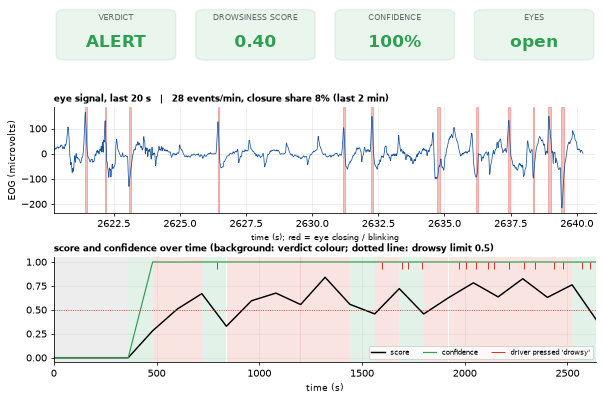

In [3]:
RECORDING = "03F_1"  # trial 1 of subjects 1-7: 01M_1 02F_1 03F_1 04M_1 05M_1 06M_1 07F_1
MINUTES = 45  # how much of the recording to play
SPEED = 60  # 60 = one minute of recording per second

path = f"data/dd_database/{RECORDING}.edf"
assert os.path.exists(path), "the recording is missing: run EOG_EDA.ipynb first (it downloads the data)"
r = pyedflib.EdfReader(path)
labels = r.getSignalLabels()
eye = r.readSignal(labels.index("LOC-Ref")) - r.readSignal(labels.index("ROC-Ref"))
r.close()  # the eye signal
a = pyedflib.EdfReader(f"data/dd_database/{RECORDING}_annotations.edf")
presses = np.array(a.readAnnotations()[0])
a.close()
presses = presses[(presses > 30) & (presses < 7000)]
FS = 128

times = np.arange(len(eye)) / FS
monitor = DrowsinessMonitor(model, FS, "eog")
replay_log = run_dashboard(SimulatedSource(times, eye, SPEED), monitor, MINUTES * 60, speed=SPEED, marks=presses)

**What the replay found.** Left: how much of the time each verdict was shown. Right: the verdict at the moment of each button press, next to the verdict over the whole time. If the detector carried real information, the DROWSY share at the presses would be clearly higher than over the whole time; if the two bars are equal it knows nothing about this driver. (Only the part after the 7.5 min of learning is counted.)

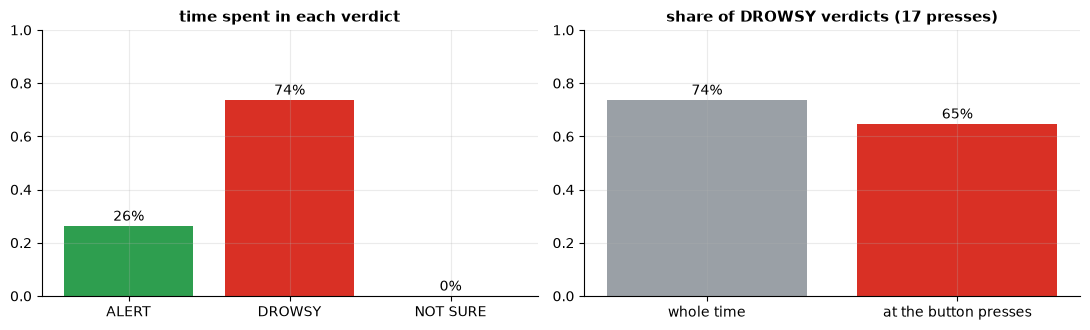

,t,verdict,score,confidence,events_per_min,closure_share
17,2042.18,DROWSY,0.78,1.0,15.5,0.05
18,2162.31,DROWSY,0.64,1.0,22.5,0.10
19,2282.19,DROWSY,0.82,1.0,15.5,0.07
20,2402.34,DROWSY,0.63,1.0,20.5,0.07
21,2522.29,DROWSY,0.76,1.0,19.0,0.09
22,2640.24,ALERT,0.40,1.0,28.5,0.08


In [4]:
ready = replay_log[replay_log.verdict.isin(["ALERT", "DROWSY", "NOT SURE"])]
share = ready.verdict.value_counts(normalize=True).reindex(["ALERT", "DROWSY", "NOT SURE"]).fillna(0)
after = presses[(presses > ready.t.min()) & (presses < MINUTES * 60)]
at_press = [ready.verdict[ready.t >= p].iloc[0] for p in after if (ready.t >= p).any()]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(share.index, share.values, color=[COLOUR[v] for v in share.index])
axes[0].set_ylim(0, 1)
axes[0].set_title("time spent in each verdict")
for k, v in enumerate(share.values):
    axes[0].text(k, v + 0.02, f"{v:.0%}", ha="center")
drowsy_at_press = np.mean([v == "DROWSY" for v in at_press]) if at_press else np.nan
axes[1].bar(["whole time", "at the button presses"], [share["DROWSY"], drowsy_at_press], color=["#9aa0a6", COLOUR["DROWSY"]])
axes[1].set_ylim(0, 1)
axes[1].set_title(f"share of DROWSY verdicts ({len(at_press)} presses)")
for k, v in enumerate([share["DROWSY"], drowsy_at_press]):
    axes[1].text(k, v + 0.02, f"{v:.0%}", ha="center")
plt.tight_layout()
plt.show()
replay_log.round(2).tail(6)

# Part B. Live sensor

## B1. Try it without a sensor (simulated EMG)
Plays a **synthetic** EMG signal with known blinks: a normal blink rate, then from second 100 only about a fifth of that (the drowsy pattern). It uses short learning times (10 s + 40 s + 30 s) so it fits in a minute, and plays 6 times faster than real time. It proves the live code works; it says nothing about EMG accuracy because the signal is not real.

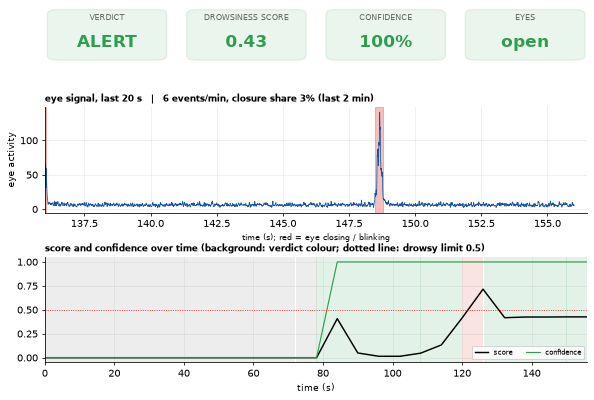

In [5]:
FS_SIM = 500
sim_t, sim_x, sim_blinks = synthetic_emg(160, FS_SIM, [(0, 16), (100, 3)], mains_hz=50.0, seed=3)
monitor = DrowsinessMonitor(model, FS_SIM, "emg", calibrate_s=10, baseline_s=40, window_s=30)
sim_log = run_dashboard(SimulatedSource(sim_t, sim_x, 6.0), monitor, 160, speed=6.0, plot_every=1.0)

## B2. Your EMG sensor
**Connect, then run the four cells below.**

1. Put the electrodes over the eyelid muscle (orbicularis oculi) at the outer corner of one eye, with the reference on the cheekbone, and connect the sensor to the laptop.
2. The sensor must send **one number per line** over USB serial (for an Arduino: `Serial.println(analogRead(A0));` repeated at a steady rate, for example every 2 ms = 500 Hz) **or** publish a Lab Streaming Layer stream. Close the Arduino Serial Monitor first, as only one program can use the port.
3. Fill in the settings. Everything that depends on your hardware is in this one block.
4. The third cell counts how many samples per second really arrive. `sample_rate_hz` must match that number: the filters and every duration are computed from it.

In [6]:
EMG_SENSOR = {
    "source": "off",  # "serial" (a board printing numbers) or "lsl" (Lab Streaming Layer). "off" = do not run
    "sample_rate_hz": 500,  # samples per second the board really sends; at least 200 (EMG is fast)
    "to_microvolts": 1.0,  # raw number x this = microvolts. ADC counts: volts_per_count x 1e6, divided by the amplifier gain
    "offset": 0.0,  # raw value at rest, e.g. 512 for a 10-bit ADC with a mid-rail offset
    "polarity": 1,  # -1 if wired the other way round
    "mains_hz": 50.0,  # India / Europe 50, USA 60
    "port": "/dev/cu.usbmodem1101",  # serial only: pick it from the list printed by the next cell
    "baudrate": 115200,
    "lsl_stream": "EMG",  # lsl only: stream name (or type)
}

In [7]:
from serial.tools import list_ports

print("serial ports on this laptop (the sensor is usually 'usbmodem...' or 'usbserial...'):")
for p in list_ports.comports():
    print("  ", p.device, "-", p.description)

serial ports on this laptop (the sensor is usually 'usbmodem...' or 'usbserial...'):
   /dev/cu.debug-console - n/a
   /dev/cu.Bluetooth-Incoming-Port - n/a
   /dev/cu.Airdopes163 - n/a
   /dev/cu.JBLFlip5 - n/a
   /dev/cu.Stone358 - n/a


In [ ]:
from drowsiness.bio.sensors import measure_rate, rate_problem

if EMG_SENSOR["source"] == "off":
    print('Set EMG_SENSOR["source"] first: this cell counts the samples the sensor really sends for 5 seconds.')
else:
    measured = measure_rate(make_source(EMG_SENSOR), seconds=5)
    if measured is None:
        print("No samples arrived: check the port, the baud rate and that nothing else (Arduino Serial Monitor) uses the port.")
    else:
        print(f"The sensor delivers about {measured:.0f} samples per second.")
        print(rate_problem(measured, EMG_SENSOR["sample_rate_hz"]) or "sample_rate_hz matches.")

**Run the sensor.** The first 7.5 minutes give no score (the detector learns *your* normal eye activity; stay awake and look ahead). Then the verdict appears. Stop it with the stop button of the notebook; the table is saved to `runs/emg_live.csv` (gitignored) when it ends.

In [8]:
if EMG_SENSOR["source"] == "off":
    print('Set EMG_SENSOR["source"] to "serial" or "lsl" in the settings cell, then run this cell again.')
else:
    fs = EMG_SENSOR["sample_rate_hz"]
    monitor = DrowsinessMonitor(
        model, fs, "emg", EMG_SENSOR["to_microvolts"], EMG_SENSOR["offset"], EMG_SENSOR["polarity"], EMG_SENSOR["mains_hz"]
    )
    live_log = run_dashboard(make_source(EMG_SENSOR), monitor, seconds=3600)
    os.makedirs("runs", exist_ok=True)
    live_log.to_csv("runs/emg_live.csv", index=False)

Set EMG_SENSOR["source"] to "serial" or "lsl" in the settings cell, then run this cell again.


### First session with the sensor: 3 checks (about 10 minutes)
1. **Does it see your blinks?** Blink on command 10 times: `events/min` and the red marks in the top plot should match. If not, check the electrode placement, `to_microvolts`, `offset` and `mains_hz`.
2. **Does bad contact lower the confidence?** Pull an electrode off: the verdict should change to `NOT SURE` within about 2 seconds.
3. **Does the score move the right way?** Hard to test on purpose; record a few real sessions with a way to mark drowsiness (like the dataset's button) and compare. Until then treat the EMG score as unvalidated.

# Part C. Pre-recorded EOG with labels, in real time (DROZY)
The detector of this notebook, using **only the EOG** (no video, no other sensor), on a recording of **DROZY** (14 people, three 10-minute tests each) played at its own speed, like a sensor. The graph shows the **EOG signal** with every detected eye event in red, the **score and confidence** under it, and the **labels**: the person's own sleepiness rating of the test (KSS 1-9) and the red ticks where the person missed or slowed on the vigilance task (a *lapse*: no reaction within 0.5 s).

* It starts as soon as you run the cell, and the detector is **ready from the first second**: it is fed the last 2.5 minutes of the person's **earlier test** first (as if the sensor had already been on), and takes the person's normal blinking from that test, so there is no learning wait. Its window still holds that earlier data at the start, so the **confidence rises from 0 to full over the first 2 minutes** while the window fills with the test itself; the first minutes of the score therefore lean on the earlier test. Test 1 of a person has no earlier test and needs 7.5 minutes of learning (try `"test": 1`).
* The model was trained on the DD-Database (another electrode pair, another lab) and is used here **without retraining**. Expect a trend, not a perfect match: over the 36 DROZY tests the mean score separates the sleepy tests (KSS 7 or more) from the others with AUC 0.71.
* Change `subject` and `test` to see another one (`drozy.tests()` lists them); `speed` > 1 plays faster than real time. The labels are only drawn, never used by the detector.
* Live sensor: not part of this section.

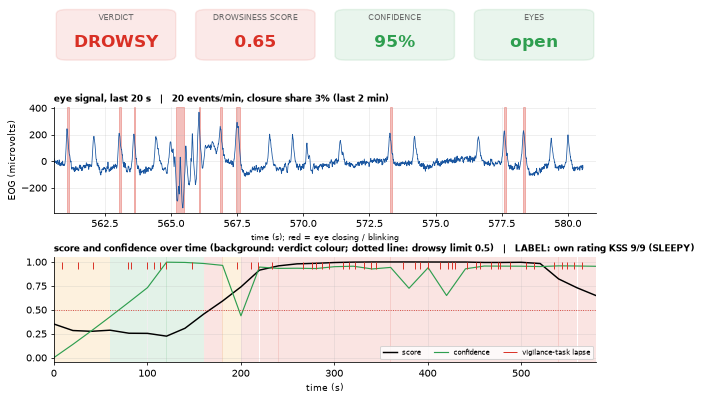

In [9]:
from drowsiness.bio import drozy
from drowsiness.bio.eye_events import CALIBRATE_S, WINDOW_S, enrol_baseline

DROZY = {"subject": 4, "test": 3, "minutes": 10, "speed": 1.0}  # test 4-3: KSS 9 (very sleepy). Try 3-1 (KSS 2, alert)

drozy_log = None
if os.path.exists(drozy.ROOT):
    sub, tst = DROZY["subject"], DROZY["test"]
    t_eog, v_eog, FS_DROZY = drozy.eog(sub, tst)
    earlier = [x for s_, x in drozy.tests() if s_ == sub and x < tst]
    baseline = None
    if earlier:  # the person's normal blinking, from their first recorded test
        t_ref, v_ref, _ = drozy.eog(sub, min(earlier))
        baseline = enrol_baseline(t_ref, v_ref, FS_DROZY, "eog")
        n_warm = int((CALIBRATE_S + WINDOW_S) * FS_DROZY)  # the end of that test: the detector starts "already running"
    kss = drozy.kss(sub, tst)
    lapse_times = [shown for shown, rt in drozy.pvt_reactions(sub, tst) if rt is None or rt > drozy.LAPSE_S]
    drozy_monitor = DrowsinessMonitor(model, FS_DROZY, "eog", baseline=baseline)
    if earlier:
        drozy_monitor.warm_up(t_ref[-n_warm:], v_ref[-n_warm:])
    drozy_log = run_dashboard(
        SimulatedSource(t_eog, v_eog, DROZY["speed"]),
        drozy_monitor,
        DROZY["minutes"] * 60,
        speed=DROZY["speed"],
        plot_every=1.0,
        marks=lapse_times,
        mark_label="vigilance-task lapse",
        note=f"   |   LABEL: own rating KSS {kss}/9 ({drozy.kss_word(kss)})",
    )
else:
    print("DROZY is not in data/drozy (download: orbi.uliege.be/handle/2268/191620); this part needs it.")

**What the detector found.** Left: how much of the time each verdict was shown. Right: the share of DROWSY verdicts over the whole time and in the 20 s after each lapse. If the EOG carried information about this person, the second bar would be clearly higher. (Only the part after the learning time is counted; one test is an illustration, not a result.)

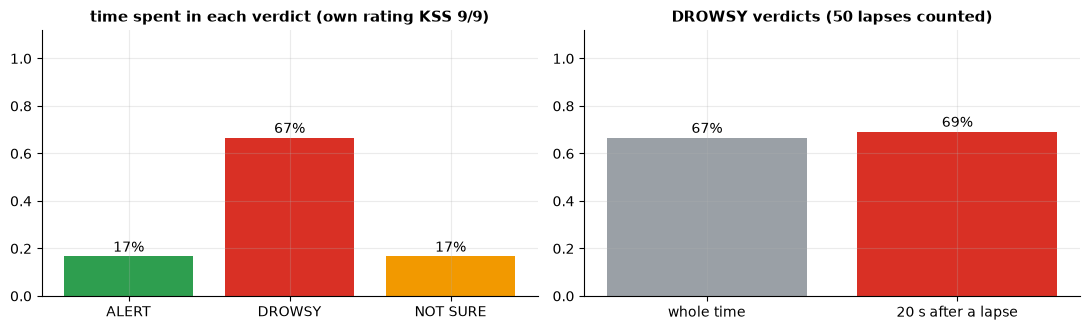

In [10]:
if drozy_log is not None:
    ready = drozy_log[drozy_log.verdict.isin(["ALERT", "DROWSY", "NOT SURE"])]
    share = ready.verdict.value_counts(normalize=True).reindex(["ALERT", "DROWSY", "NOT SURE"]).fillna(0)
    after = [x for x in lapse_times if x > ready.t.min()]
    near_lapse = ready[[any(0 <= tt - x <= 20 for x in after) for tt in ready.t]]
    drowsy_after_lapse = (near_lapse.verdict == "DROWSY").mean() if len(near_lapse) else np.nan

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    axes[0].bar(share.index, share.values, color=[COLOUR[v] for v in share.index])
    axes[0].set_ylim(0, 1.12)
    axes[0].set_title(f"time spent in each verdict (own rating KSS {kss}/9)")
    for k, v in enumerate(share.values):
        axes[0].text(k, v + 0.02, f"{v:.0%}", ha="center")
    bars = [share["DROWSY"], drowsy_after_lapse]
    axes[1].bar(["whole time", "20 s after a lapse"], bars, color=["#9aa0a6", COLOUR["DROWSY"]])
    axes[1].set_ylim(0, 1.12)
    axes[1].set_title(f"DROWSY verdicts ({len(after)} lapses counted)")
    for k, v in enumerate(bars):
        axes[1].text(k, (0 if np.isnan(v) else v) + 0.02, "-" if np.isnan(v) else f"{v:.0%}", ha="center")
    plt.tight_layout()
    plt.show()